# Fine-tuning Run Analysis
Analyses all runs under `text_classifier/fine_tuning/` and cross-references predictions with the original training texts.

In [13]:
import re
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from pathlib import Path
from sklearn.metrics import confusion_matrix, classification_report

%matplotlib inline
plt.rcParams['figure.dpi'] = 120

## 1. Paths

In [14]:
ROOT = Path(".")  # run from text_classifier/ or adjust
FT_DIR = ROOT / "fine_tuning"
TRAIN_CSV = ROOT / "data" / "train.csv"

run_dirs = sorted([p for p in FT_DIR.iterdir() if p.is_dir()])
print(f"Found {len(run_dirs)} runs:")
for r in run_dirs:
    print(" ", r.name)

Found 8 runs:
  xlm-roberta-base_full_lr1.00e-05_ep5
  xlm-roberta-base_full_lr1.00e-05_ep8
  xlm-roberta-base_full_lr2.00e-05_ep5
  xlm-roberta-base_full_lr5.00e-05_ep5
  xlm-roberta-base_full_lr5.00e-05_ep8
  xlm-roberta-base_full_lr8.00e-06_ep5
  xlm-roberta-base_lora_lr5.00e-04_ep3
  xlm-roberta-base_lora_lr5.00e-04_ep5


## 2. Load data

In [15]:
train_df = pd.read_csv(TRAIN_CSV)
print(f"train.csv: {len(train_df):,} rows  |  columns: {list(train_df.columns)}")
train_df.head(3)

train.csv: 252,000 rows  |  columns: ['id', 'sentence', 'label']


,id,sentence,label
0,0,Moderner Weihnachtsbaum in weiß\n\nDieses Jahr...,4
1,1,Passt wie angegossen\n\nTasche kam schnell und...,4
2,2,Schlechte Qualität\n\nIch habe sehr lange auf ...,1


In [16]:
def parse_metrics(path: Path) -> dict:
    """Parse validation_metrics.txt into a flat dict."""
    text = path.read_text()
    m = {}
    for line in text.splitlines():
        line = line.strip()
        if line.startswith("Overall Accuracy:"):
            m["accuracy"] = float(line.split(":")[1])
        elif line.startswith("Overall Score:"):
            m["score"] = float(line.split(":")[1])
        elif "MAE =" in line:
            label = int(re.search(r"Label (\d+)", line).group(1))
            val = float(line.split("MAE =")[1])
            m[f"mae_label_{label}"] = val
        elif "Accuracy =" in line:
            label = int(re.search(r"Label (\d+)", line).group(1))
            val = float(line.split("Accuracy =")[1])
            m[f"acc_label_{label}"] = val
    return m


runs = {}
for rdir in run_dirs:
    name = rdir.name
    entry = {"name": name, "path": rdir}

    metrics_file = rdir / "validation_metrics.txt"
    if metrics_file.exists():
        entry.update(parse_metrics(metrics_file))

    val_file = rdir / "validation_results.csv"
    if val_file.exists():
        vdf = pd.read_csv(val_file)
        merged = vdf.merge(train_df[["id", "sentence"]], on="id", how="left")
        entry["val_df"] = merged

    mistakes_file = rdir / "big_mistakes.csv"
    if mistakes_file.exists():
        mdf = pd.read_csv(mistakes_file)
        mdf = mdf.merge(train_df[["id", "sentence"]], on="id", how="left")
        entry["mistakes_df"] = mdf

    runs[name] = entry

print("Loaded runs:", list(runs.keys()))

Loaded runs: ['xlm-roberta-base_full_lr1.00e-05_ep5', 'xlm-roberta-base_full_lr1.00e-05_ep8', 'xlm-roberta-base_full_lr2.00e-05_ep5', 'xlm-roberta-base_full_lr5.00e-05_ep5', 'xlm-roberta-base_full_lr5.00e-05_ep8', 'xlm-roberta-base_full_lr8.00e-06_ep5', 'xlm-roberta-base_lora_lr5.00e-04_ep3', 'xlm-roberta-base_lora_lr5.00e-04_ep5']


## 3. Overall metrics comparison

In [17]:
metrics_rows = []
for name, r in runs.items():
    row = {"run": name}
    for k in ["accuracy", "score", "mae_label_0", "mae_label_1", "mae_label_2", "mae_label_3", "mae_label_4",
              "acc_label_0", "acc_label_1", "acc_label_2", "acc_label_3", "acc_label_4"]:
        row[k] = r.get(k, float("nan"))
    metrics_rows.append(row)

metrics_df = pd.DataFrame(metrics_rows).set_index("run")
metrics_df.sort_values("score", ascending=False).style.background_gradient(axis=0, cmap="RdYlGn")

,accuracy,score,mae_label_0,mae_label_1,mae_label_2,mae_label_3,mae_label_4,acc_label_0,acc_label_1,acc_label_2,acc_label_3,acc_label_4
run,,,,,,,,,,,,
xlm-roberta-base_full_lr1.00e-05_ep5,0.661900,0.905500,0.312300,0.442100,0.522300,0.428400,0.184600,0.742000,0.583900,0.548100,0.599200,0.837100
xlm-roberta-base_full_lr8.00e-06_ep5,0.661300,0.905100,0.309700,0.450800,0.518700,0.430400,0.188300,0.745800,0.575600,0.554600,0.597700,0.833500
xlm-roberta-base_full_lr5.00e-05_ep5,0.657500,0.904000,0.331300,0.442100,0.515000,0.427400,0.203200,0.726700,0.588300,0.547700,0.601800,0.823600
xlm-roberta-base_full_lr2.00e-05_ep5,0.655700,0.903800,0.327800,0.445700,0.520900,0.431200,0.198300,0.729300,0.584300,0.542600,0.598200,0.824800
xlm-roberta-base_lora_lr5.00e-04_ep5,0.656600,0.903700,0.308900,0.452200,0.534500,0.445400,0.184800,nan,nan,nan,nan,nan
xlm-roberta-base_full_lr1.00e-05_ep8,0.655200,0.903500,0.333700,0.451800,0.516400,0.435200,0.192100,0.727900,0.576400,0.548100,0.593900,0.830500
xlm-roberta-base_lora_lr5.00e-04_ep3,0.654100,0.902400,0.304700,0.468100,0.541000,0.460700,0.177200,nan,nan,nan,nan,nan
xlm-roberta-base_full_lr5.00e-05_ep8,0.638800,0.897900,0.386400,0.458600,0.534500,0.447100,0.214900,0.690500,0.574600,0.531300,0.584500,0.813900


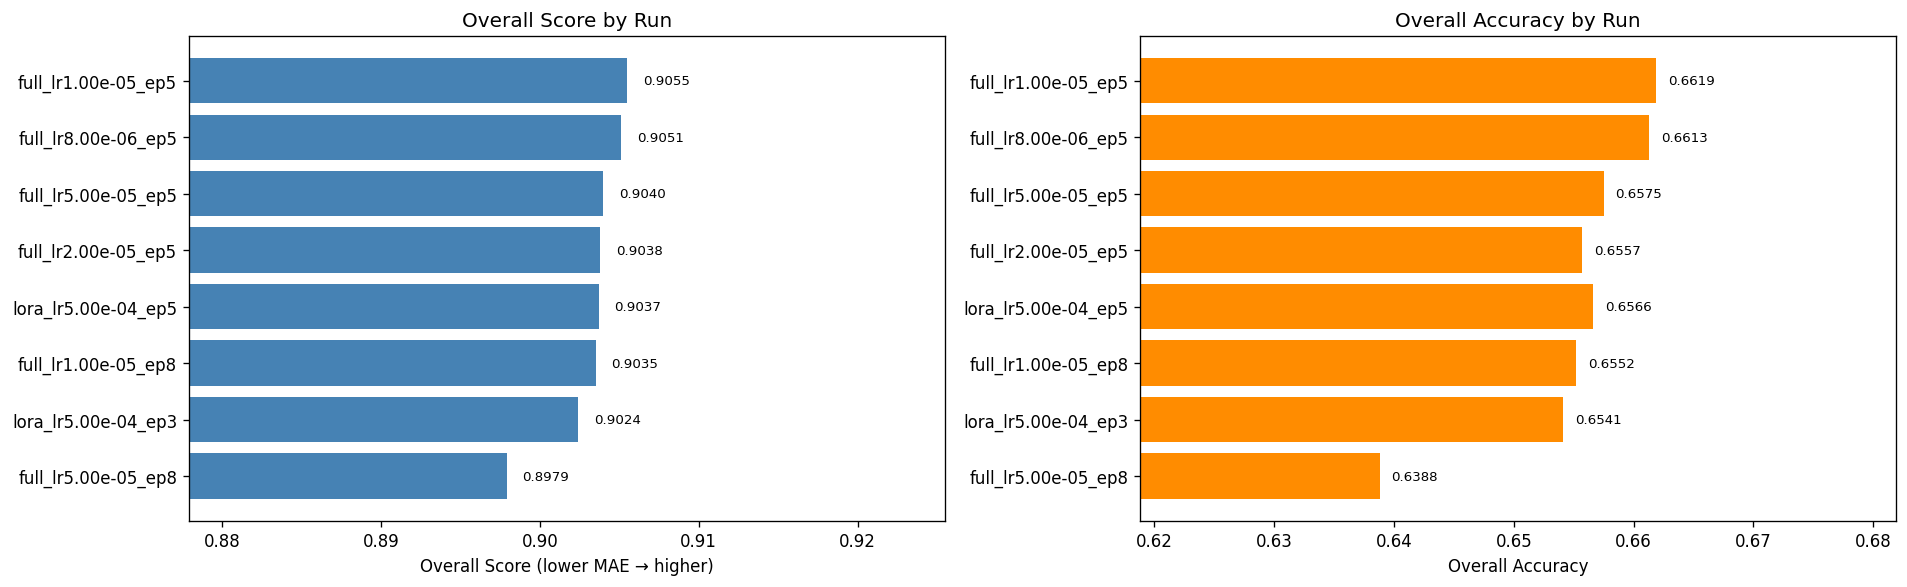

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
short_names = [n.replace("xlm-roberta-base_", "") for n in metrics_df.index]

sorted_idx = metrics_df["score"].sort_values(ascending=True).index
vals_score = metrics_df.loc[sorted_idx, "score"]
vals_acc = metrics_df.loc[sorted_idx, "accuracy"]
labels = [n.replace("xlm-roberta-base_", "") for n in sorted_idx]

axes[0].barh(labels, vals_score, color="steelblue")
axes[0].set_xlabel("Overall Score (lower MAE → higher)")
axes[0].set_title("Overall Score by Run")
axes[0].set_xlim(max(0, vals_score.min() - 0.02), min(1, vals_score.max() + 0.02))
for i, v in enumerate(vals_score):
    axes[0].text(v + 0.001, i, f"{v:.4f}", va="center", fontsize=8)

axes[1].barh(labels, vals_acc, color="darkorange")
axes[1].set_xlabel("Overall Accuracy")
axes[1].set_title("Overall Accuracy by Run")
axes[1].set_xlim(max(0, vals_acc.min() - 0.02), min(1, vals_acc.max() + 0.02))
for i, v in enumerate(vals_acc):
    axes[1].text(v + 0.001, i, f"{v:.4f}", va="center", fontsize=8)

plt.tight_layout()
plt.show()

## 4. Per-label accuracy and MAE across runs

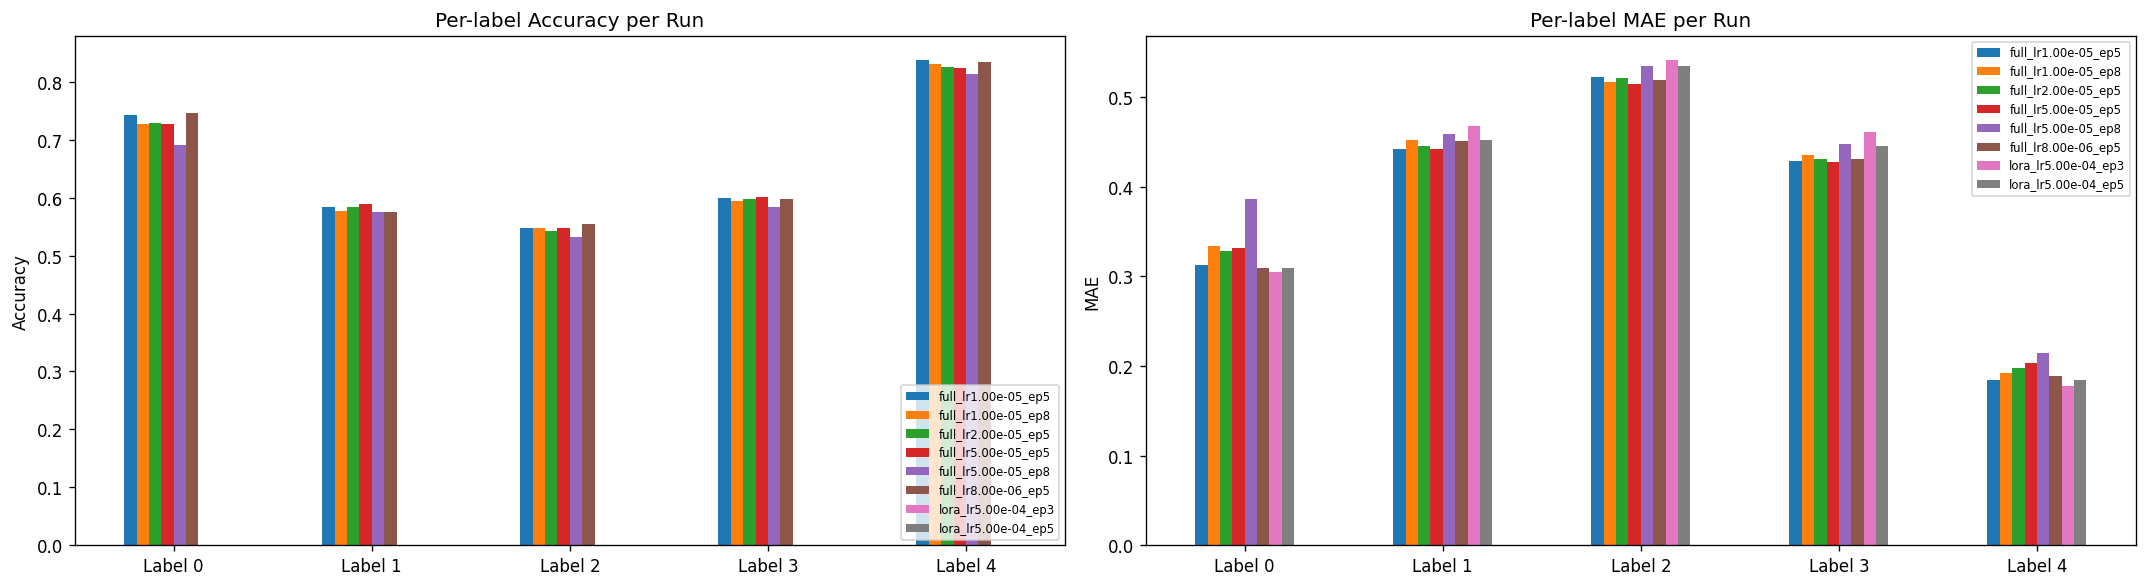

In [19]:
acc_cols = [f"acc_label_{i}" for i in range(5)]
mae_cols = [f"mae_label_{i}" for i in range(5)]
short_index = [n.replace("xlm-roberta-base_", "") for n in metrics_df.index]

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

acc_data = metrics_df[acc_cols].copy()
acc_data.index = short_index
acc_data.columns = [f"Label {i}" for i in range(5)]
acc_data.T.plot(kind="bar", ax=axes[0], rot=0)
axes[0].set_title("Per-label Accuracy per Run")
axes[0].set_ylabel("Accuracy")
axes[0].legend(loc="lower right", fontsize=7)

mae_data = metrics_df[mae_cols].copy()
mae_data.index = short_index
mae_data.columns = [f"Label {i}" for i in range(5)]
mae_data.T.plot(kind="bar", ax=axes[1], rot=0)
axes[1].set_title("Per-label MAE per Run")
axes[1].set_ylabel("MAE")
axes[1].legend(loc="upper right", fontsize=7)

plt.tight_layout()
plt.show()

## 5. Confusion matrices

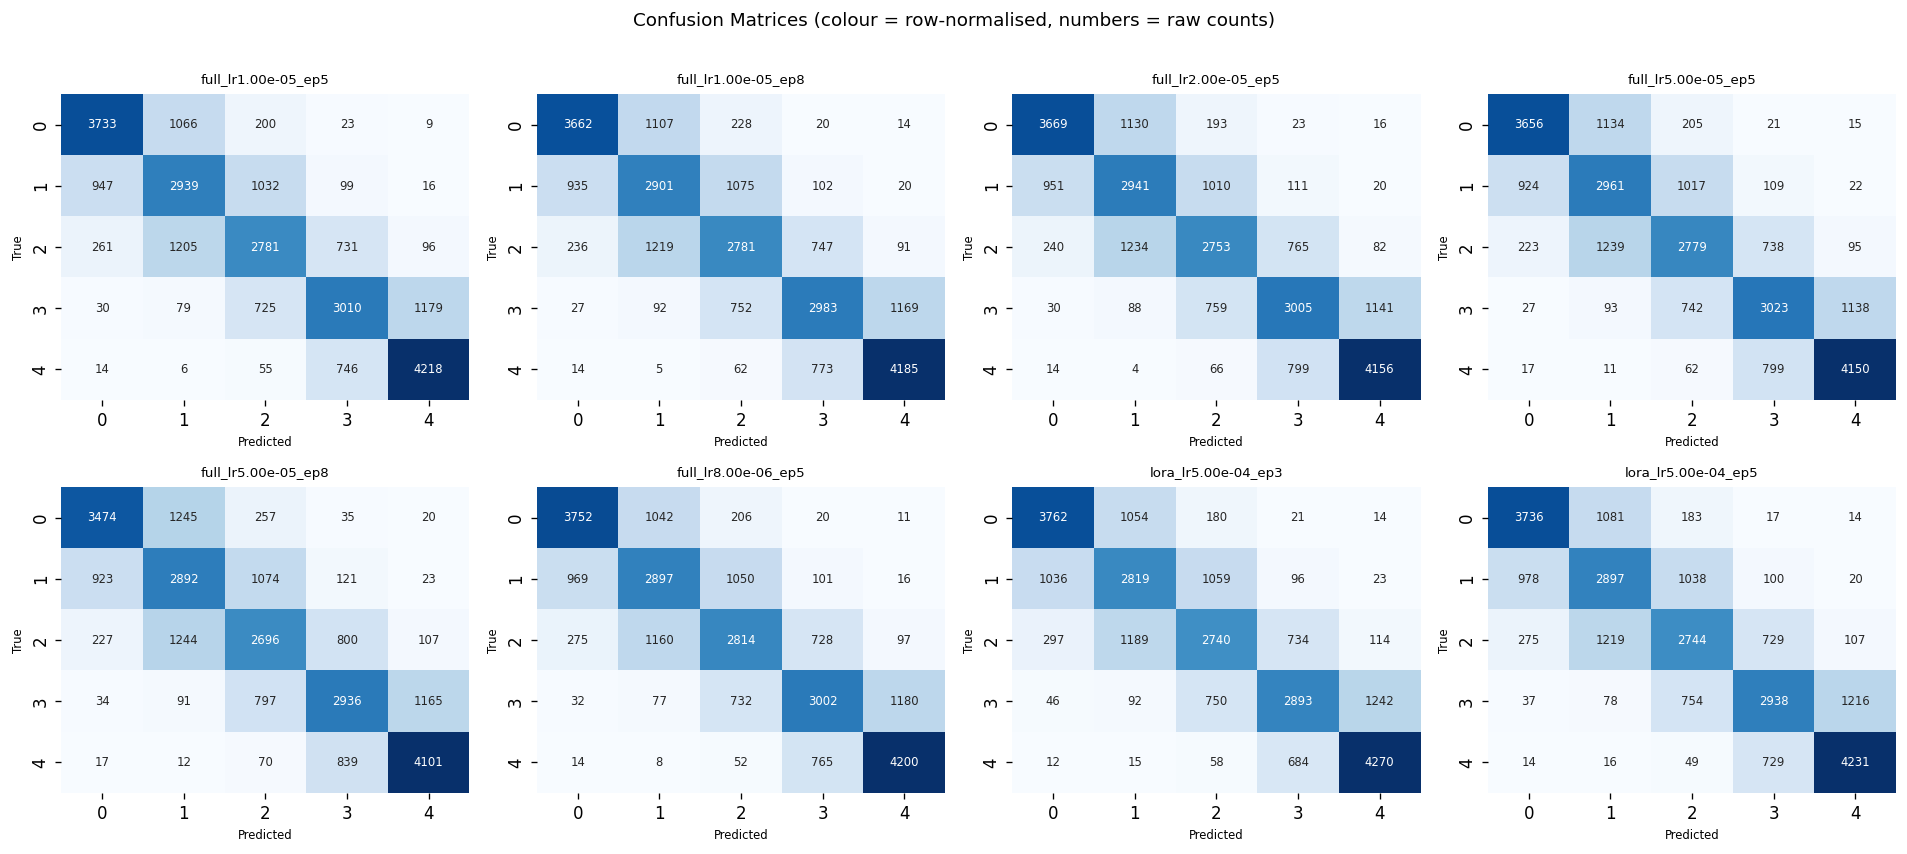

In [20]:
LABELS = [0, 1, 2, 3, 4]
n = len(runs)
ncols = 4
nrows = (n + ncols - 1) // ncols

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 3.5))
axes = axes.flatten()

for i, (name, r) in enumerate(runs.items()):
    ax = axes[i]
    if "val_df" not in r:
        ax.set_visible(False)
        continue
    vdf = r["val_df"]
    cm = confusion_matrix(vdf["true_label"], vdf["predicted_label"], labels=LABELS)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_norm, annot=cm, fmt="d", ax=ax, cmap="Blues",
                xticklabels=LABELS, yticklabels=LABELS,
                cbar=False, annot_kws={"size": 7})
    ax.set_title(name.replace("xlm-roberta-base_", ""), fontsize=8)
    ax.set_xlabel("Predicted", fontsize=7)
    ax.set_ylabel("True", fontsize=7)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Confusion Matrices (colour = row-normalised, numbers = raw counts)", fontsize=11, y=1.01)
plt.tight_layout()
plt.show()

## 6. Prediction error distribution

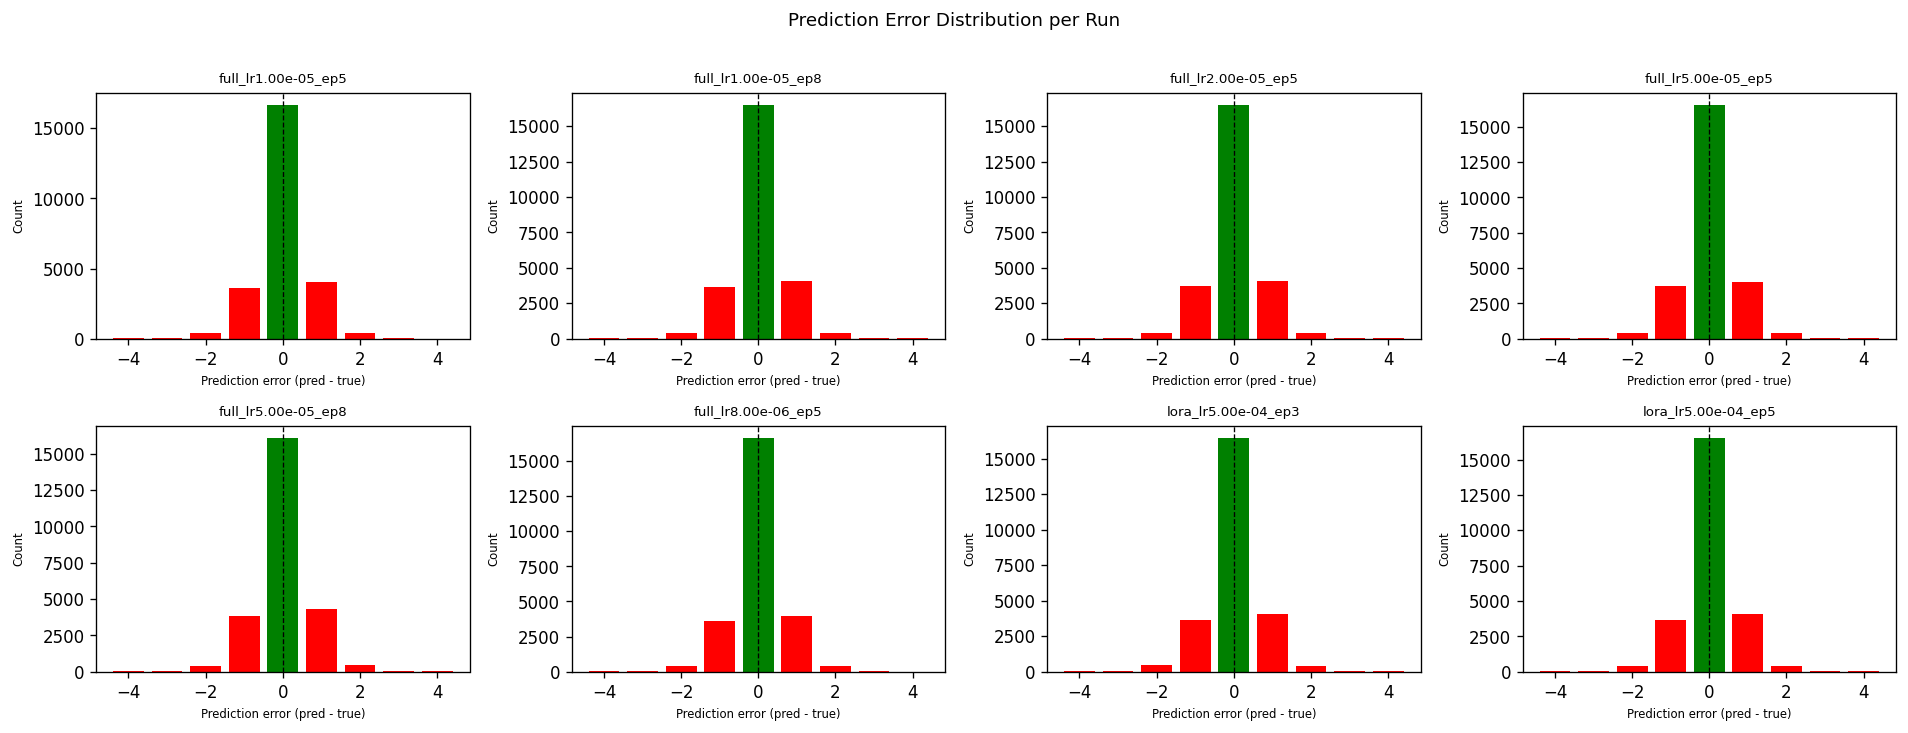

In [21]:
fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 3))
axes = axes.flatten()

for i, (name, r) in enumerate(runs.items()):
    ax = axes[i]
    if "val_df" not in r:
        ax.set_visible(False)
        continue
    vdf = r["val_df"]
    errors = vdf["predicted_label"] - vdf["true_label"]
    error_counts = errors.value_counts().sort_index()
    ax.bar(error_counts.index, error_counts.values,
           color=["red" if x != 0 else "green" for x in error_counts.index])
    ax.axvline(0, color="black", linewidth=0.8, linestyle="--")
    ax.set_title(name.replace("xlm-roberta-base_", ""), fontsize=8)
    ax.set_xlabel("Prediction error (pred - true)", fontsize=7)
    ax.set_ylabel("Count", fontsize=7)

for j in range(i + 1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Prediction Error Distribution per Run", fontsize=11, y=1.01)
plt.tight_layout()
plt.show()

## 7. Sample agreement across runs

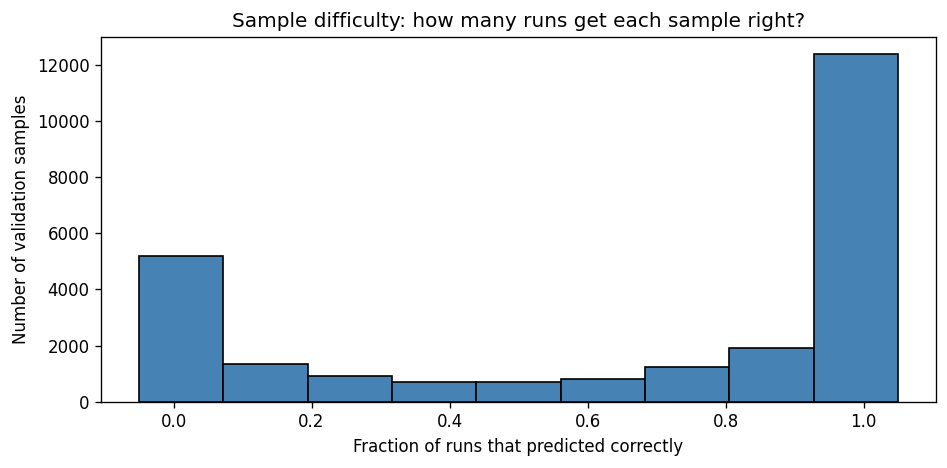

Always correct (all runs): 12,375
Never correct (no run): 5,178


In [22]:
# Build a wide table: one row per validation sample, one column per run
all_val = None
for name, r in runs.items():
    if "val_df" not in r:
        continue
    cols = r["val_df"][["id", "true_label", "predicted_label"]].rename(
        columns={"predicted_label": name})
    if all_val is None:
        all_val = cols
    else:
        all_val = all_val.merge(cols[["id", name]], on="id", how="outer")

run_cols = list(runs.keys())
if all_val is not None:
    # How many runs agree with the true label per sample
    all_val["n_correct"] = (all_val[run_cols].values == all_val["true_label"].values[:, None]).sum(axis=1)
    all_val["n_runs"] = all_val[run_cols].notna().sum(axis=1)
    all_val["pct_correct"] = all_val["n_correct"] / all_val["n_runs"]

    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(all_val["pct_correct"], bins=all_val["n_runs"].max() + 1,
            range=(-0.05, 1.05), edgecolor="black", color="steelblue")
    ax.set_xlabel("Fraction of runs that predicted correctly")
    ax.set_ylabel("Number of validation samples")
    ax.set_title("Sample difficulty: how many runs get each sample right?")
    plt.tight_layout()
    plt.show()

    print(f"Always correct (all runs): {(all_val['n_correct'] == all_val['n_runs']).sum():,}")
    print(f"Never correct (no run): {(all_val['n_correct'] == 0).sum():,}")

## 8. Samples no run ever gets right (hardest examples)

In [38]:
if all_val is not None:
    hardest = all_val[all_val["n_correct"] == 0].merge(
        train_df[["id", "sentence"]], on="id", how="left")
    hardest = hardest.sort_values("true_label")
    print(f"Hardest samples (never correct across all runs): {len(hardest):,}")
    display(hardest[["id", "true_label"] + run_cols + ["sentence"]].tail(20))
    print(hardest.groupby("true_label").size())
   

Hardest samples (never correct across all runs): 5,178


,id,true_label,xlm-roberta-base_full_lr1.00e-05_ep5,xlm-roberta-base_full_lr1.00e-05_ep8,xlm-roberta-base_full_lr2.00e-05_ep5,xlm-roberta-base_full_lr5.00e-05_ep5,xlm-roberta-base_full_lr5.00e-05_ep8,xlm-roberta-base_full_lr8.00e-06_ep5,xlm-roberta-base_lora_lr5.00e-04_ep3,xlm-roberta-base_lora_lr5.00e-04_ep5,sentence
4495,218550,4,3,3,3,3,3,3,3,3,"Decent quality\n\nGood price, good product"
1861,89351,4,3,3,3,3,3,3,3,3,"Bang for your buck\n\nHaven’t had a chance to actually use them yet and really hope I never have to come into that situation. First impression is good, sturdy shears and they are pretty sharp. I did test them out on some thicker paper and they cut like a champ"
1866,89522,4,3,3,3,3,3,3,3,3,"Slow to warm up, but otherwise good\n\nSanta gave my wife a massage table with this warmer for Christmas. The warmer works pretty well but we find it takes a while for it to warm up. It has decent controls and we end up turning it down a little after a while. I would but it again in a heartbeat."
1870,89698,4,0,0,0,0,0,0,0,0,Digital\n\nWas a digital copy not a physical.
3398,164070,4,3,3,3,3,3,3,3,3,"Super cute, a little smaller than I expected\n\nSuper cute, a little smaller than I expected, but can't beat the price."
4508,219019,4,3,3,3,3,3,3,3,3,"Our stray furkid seems to be doing very well in ...\n\nOur stray furkid seems to be doing very well in the below 0 temps, thanks to this warmed house. We did however place this inside of a bigger wooden cat house."
713,32810,4,3,3,3,2,2,3,3,3,Thirst quenching.\n\nLiked the variety and price.
705,32633,4,3,3,3,3,3,3,3,3,"Good for bigger laptops\n\nSuper comfy lapdesk even with my heavy MSI 17.5"" gaming laptop. My legs no longer burn after 20 minutes, I don't have to turn on the turbo fan, and I can move around without feeling like the whole ship is going to sink. It looks nice to boot! The only drawback is that ..."
732,33901,4,3,3,3,3,3,3,3,3,Product as described and pictured\n\nA bit expensive for a coffee mug but if you've got a friends fan in your life it's a good gift. Smaller than the mugs they drink out of on the show but the ones the cast drinks out of on the show are generic coffee mugs without logos so it's fine.
4517,219495,4,3,3,3,3,3,3,3,3,Gloves\n\nSuper comfy. These run a little small but they are warm and great for lighter glove options.


true_label
0     837
1    1133
2    1414
3    1309
4     485
dtype: int64


## 9. Big mistakes deep-dive

Inspecting best run by score: xlm-roberta-base_full_lr1.00e-05_ep5

888 big-mistake samples

Error distribution:


,count
error,
-4,14
-3,36
-2,395
2,395
3,39
4,9


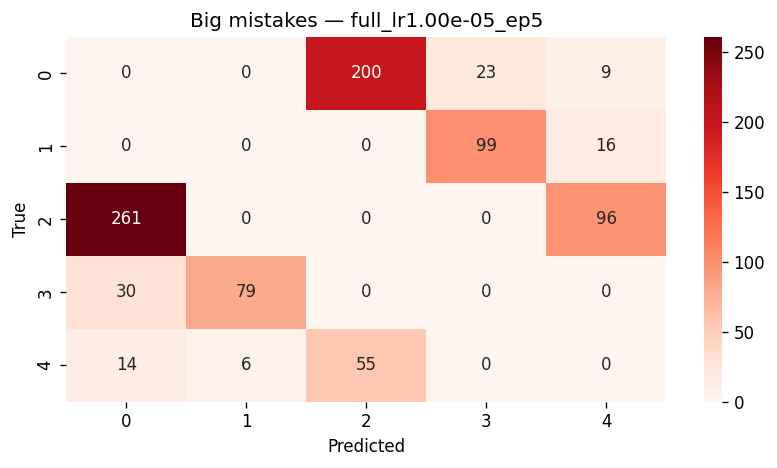

In [24]:
# Choose which run to inspect (change index or name)
INSPECT_RUN = sorted(runs.keys(), key=lambda k: runs[k].get("score", 0), reverse=True)[0]
print(f"Inspecting best run by score: {INSPECT_RUN}")

r = runs[INSPECT_RUN]
if "mistakes_df" in r:
    mdf = r["mistakes_df"]
    mdf["error"] = mdf["predicted_label"] - mdf["true_label"]
    print(f"\n{len(mdf)} big-mistake samples")
    print("\nError distribution:")
    display(mdf["error"].value_counts().sort_index().to_frame())

    fig, ax = plt.subplots(figsize=(7, 4))
    pivot = mdf.groupby(["true_label", "predicted_label"]).size().unstack(fill_value=0)
    sns.heatmap(pivot, annot=True, fmt="d", cmap="Reds", ax=ax)
    ax.set_title(f"Big mistakes — {INSPECT_RUN.replace('xlm-roberta-base_', '')}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    plt.tight_layout()
    plt.show()
else:
    print("No big_mistakes.csv found for this run.")

### Browse big-mistake samples (with text)

In [39]:
TRUE_LABEL_FILTER = None   # set to an int (0-4) to filter, or None for all
N_SAMPLES = 50

if "mistakes_df" in r:
    view = r["mistakes_df"].copy()
    if TRUE_LABEL_FILTER is not None:
        view = view[view["true_label"] == TRUE_LABEL_FILTER]
    view = view.sample(min(N_SAMPLES, len(view)), random_state=42)
    pd.set_option("display.max_colwidth", 300)
    display(view[["id", "true_label", "predicted_label", "sentence"]])

,id,true_label,predicted_label,sentence
280,163995,0,2,Wish the quality was better\n\nThese tops would be great except the strap broke after wearing it once.
434,106249,1,3,"Oy vey!\n\nLooks great on him, tight though apparently but the pink set fit better"
39,66111,2,0,Aua!\n\nHab allergisch drauf reagiert war sehr entzündet.. Verschluss ist schnell abgenutzt und dreht durch
417,67672,2,0,Bringt leider gar nix\n\nLeider bringt das Spray gar nix. Trotz sofortigen anwenden bleibt der Fleck und der Geruch vorhanden.
584,223744,1,3,"Two is generous\n\nGreat ass and tits which overrides horrible writing, I mean just awful nonsensical crap dialogue. The girls are hot though."
803,197410,0,2,Deutsche Beschreibung ??????\n\nWo bleibt bitte eine Deutsche Beschreibung ???
342,241157,2,0,"Fernglas Buddygo 10x42\n\nDas Fernglas riecht extrem nach Gummi, kann man meiner Meinung nach nicht verwenden. Die Bildqualität ist nicht gut, das Gerät wurde zurückgeschickt."
834,30016,4,2,Not what I expected.\n\nI throughly enjoyed this book but it was not what I expected from a Dean Koontz novel. I would definitely recommend it.
580,3493,2,0,"Jacke passt nicht\n\nJacke passt nicht zur angegebenen Größe ! Schade das es die Jacke nicht noch etwas größer gibt . Für meine Tochter groß genug , sonst hätte ich sie zurück gesendet !"
536,2801,1,3,"Verpackung mit Plastik\n\nUm Plastik zu sparen bin ich auf Papierstrohhalme umgestiegen und habe schon verschiedene ausprobiert. Aber wie kommt man auf die Idee, einen Papier Karton und Papier Strohhalme zu produzieren und dann die Strohhalme in Plastik zu verpacken??"


## 10. Per-run classification report

In [26]:
REPORT_RUN = INSPECT_RUN  # change to any run name

r = runs[REPORT_RUN]
if "val_df" in r:
    vdf = r["val_df"]
    print(f"Classification report — {REPORT_RUN}\n")
    print(classification_report(vdf["true_label"], vdf["predicted_label"],
                                labels=LABELS, digits=4))

Classification report — xlm-roberta-base_full_lr1.00e-05_ep5

              precision    recall  f1-score   support

           0     0.7488    0.7420    0.7454      5031
           1     0.5551    0.5839    0.5691      5033
           2     0.5802    0.5481    0.5637      5074
           3     0.6531    0.5992    0.6250      5023
           4     0.7644    0.8371    0.7991      5039

    accuracy                         0.6619     25200
   macro avg     0.6603    0.6621    0.6605     25200
weighted avg     0.6602    0.6619    0.6603     25200



## 11. Label distribution in validation set

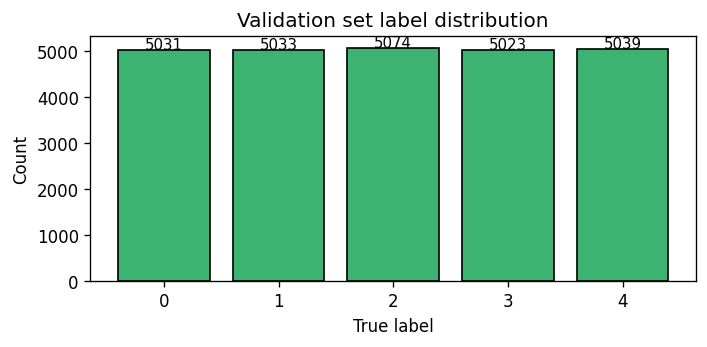

In [27]:
first_run = next(r for r in runs.values() if "val_df" in r)
label_counts = first_run["val_df"]["true_label"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(label_counts.index, label_counts.values, color="mediumseagreen", edgecolor="black")
ax.set_xlabel("True label")
ax.set_ylabel("Count")
ax.set_title("Validation set label distribution")
for x, v in zip(label_counts.index, label_counts.values):
    ax.text(x, v + 20, str(v), ha="center", fontsize=9)
plt.tight_layout()
plt.show()

## 12. Explore a specific sample across runs

In [28]:
SAMPLE_ID = None  # set to an int id to inspect, e.g. 14894

if SAMPLE_ID is not None and all_val is not None:
    row = all_val[all_val["id"] == SAMPLE_ID]
    text_row = train_df[train_df["id"] == SAMPLE_ID]
    if not row.empty:
        true_lbl = row["true_label"].iloc[0]
        print(f"Sample ID: {SAMPLE_ID}")
        print(f"True label: {true_lbl}")
        print("\nPredictions per run:")
        for c in run_cols:
            pred = row[c].iloc[0]
            marker = "✓" if pred == true_lbl else "✗"
            print(f"  {marker} {c.replace('xlm-roberta-base_', '')}: {pred}")
        if not text_row.empty:
            print("\nText:")
            print(text_row["sentence"].iloc[0])
    else:
        print(f"ID {SAMPLE_ID} not found in validation results.")

## 13. Ensemble analysis

Compares four ensembling strategies against each individual run on the shared validation set:

| Strategy | Description |
|---|---|
| **Majority vote** | Each run casts one vote; ties broken by rounding the mean |
| **Mean (rounded)** | Round the unweighted mean of all predictions |
| **Score-weighted mean** | Weight each run's prediction by its validation `score`; round result |
| **Top-k majority vote** | Majority vote using only the *k* best runs by score |


In [57]:
# ── helpers ──────────────────────────────────────────────────────────────────

def compute_metrics(true_labels, predicted_labels):
    """Return (accuracy, score) where score = 1 - mean_abs_error / 4."""
    true = np.array(true_labels)
    pred = np.array(predicted_labels)
    accuracy = (true == pred).mean()
    score = 1.0 - np.abs(true - pred).mean() / 4.0
    return accuracy, score


def majority_vote(pred_matrix):
    """Row-wise majority vote; ties broken by the rounded mean."""
    result = []
    for row in pred_matrix:
        counts = np.bincount(row.astype(int), minlength=5)
        max_count = counts.max()
        candidates = np.where(counts == max_count)[0]
        if len(candidates) == 1:
            result.append(candidates[0])
        else:
            result.append(int(np.round(row.mean())))
    return np.array(result)


# ── build shared prediction matrix ───────────────────────────────────────────

valid_runs = {k: v for k, v in runs.items() if "val_df" in v and ('full_lr1' in k or 'lora_lr5' in k)}
run_names  = list(valid_runs.keys())
short_run_names = [n.replace("xlm-roberta-base_", "") for n in run_names]

# Intersect sample IDs so all runs share the same rows
common_ids = None
for name in run_names:
    ids = set(valid_runs[name]["val_df"]["id"])
    common_ids = ids if common_ids is None else common_ids & ids
common_ids = np.array(sorted(common_ids))

# True labels (same for every run on shared IDs)
id_to_true = valid_runs[run_names[0]]["val_df"].set_index("id")["true_label"]
true_labels = id_to_true.loc[common_ids].values

# Prediction matrix  (n_samples × n_runs)
pred_cols = []
for name in run_names:
    col = (valid_runs[name]["val_df"]
           .set_index("id")
           .loc[common_ids, "predicted_label"]
           .values)
    pred_cols.append(col)

pred_matrix = np.stack(pred_cols, axis=1)
run_scores  = np.array([runs[n].get("score", 0.0) for n in run_names])

print(f"Prediction matrix shape : {pred_matrix.shape}  (samples × runs)")
print(f"Common validation samples: {len(common_ids):,}")
print("\nRun scores used for weighting:")
for name, s in zip(short_run_names, run_scores):
    print(f"  {name}: {s:.4f}")

Prediction matrix shape : (25200, 4)  (samples × runs)
Common validation samples: 25,200

Run scores used for weighting:
  full_lr1.00e-05_ep5: 0.9055
  full_lr1.00e-05_ep8: 0.9035
  lora_lr5.00e-04_ep3: 0.9024
  lora_lr5.00e-04_ep5: 0.9037


In [58]:
# ── compute all ensemble strategies ──────────────────────────────────────────

ensemble_results = []

# Individual runs (baseline)
for i, name in enumerate(run_names):
    acc, sc = compute_metrics(true_labels, pred_matrix[:, i])
    ensemble_results.append({
        "label": short_run_names[i],
        "type": "individual",
        "accuracy": acc,
        "score": sc,
    })

# Strategy 1 – Majority vote (all runs)
mv_pred = majority_vote(pred_matrix)
acc, sc = compute_metrics(true_labels, mv_pred)
ensemble_results.append({"label": "majority_vote_all", "type": "ensemble", "accuracy": acc, "score": sc})

# Strategy 2 – Mean rounded (all runs)
mean_pred = np.clip(np.round(pred_matrix.mean(axis=1)), 0, 4).astype(int)
acc, sc = compute_metrics(true_labels, mean_pred)
ensemble_results.append({"label": "mean_rounded_all", "type": "ensemble", "accuracy": acc, "score": sc})

# Strategy 3 – Score-weighted mean (all runs)
weights = run_scores / run_scores.sum()
weighted_pred = np.clip(np.round((pred_matrix * weights).sum(axis=1)), 0, 4).astype(int)
acc, sc = compute_metrics(true_labels, weighted_pred)
ensemble_results.append({"label": "score_weighted_all", "type": "ensemble", "accuracy": acc, "score": sc})

# Strategy 4 – Top-k majority vote for k in {2, 3, 4, 5}
sorted_run_idx = np.argsort(run_scores)[::-1]
for k in range(2, min(6, len(run_names) + 1)):
    top_k_idx = sorted_run_idx[:k]
    top_k_names = " + ".join(short_run_names[i] for i in top_k_idx)
    topk_pred = majority_vote(pred_matrix[:, top_k_idx])
    acc, sc = compute_metrics(true_labels, topk_pred)
    ensemble_results.append({
        "label": f"top{k}_majority_vote",
        "type": "ensemble",
        "accuracy": acc,
        "score": sc,
        "note": top_k_names,
    })

ens_df = pd.DataFrame(ensemble_results).sort_values("score", ascending=False).reset_index(drop=True)
print(ens_df[["label", "type", "accuracy", "score"]].to_string(index=False))

              label       type  accuracy    score
 score_weighted_all   ensemble  0.663532 0.906488
 top3_majority_vote   ensemble  0.662817 0.906032
full_lr1.00e-05_ep5 individual  0.661944 0.905476
   mean_rounded_all   ensemble  0.660476 0.905119
  majority_vote_all   ensemble  0.661032 0.904911
 top4_majority_vote   ensemble  0.661032 0.904911
 top2_majority_vote   ensemble  0.658730 0.904008
lora_lr5.00e-04_ep5 individual  0.656587 0.903671
full_lr1.00e-05_ep8 individual  0.655238 0.903502
lora_lr5.00e-04_ep3 individual  0.654127 0.902371


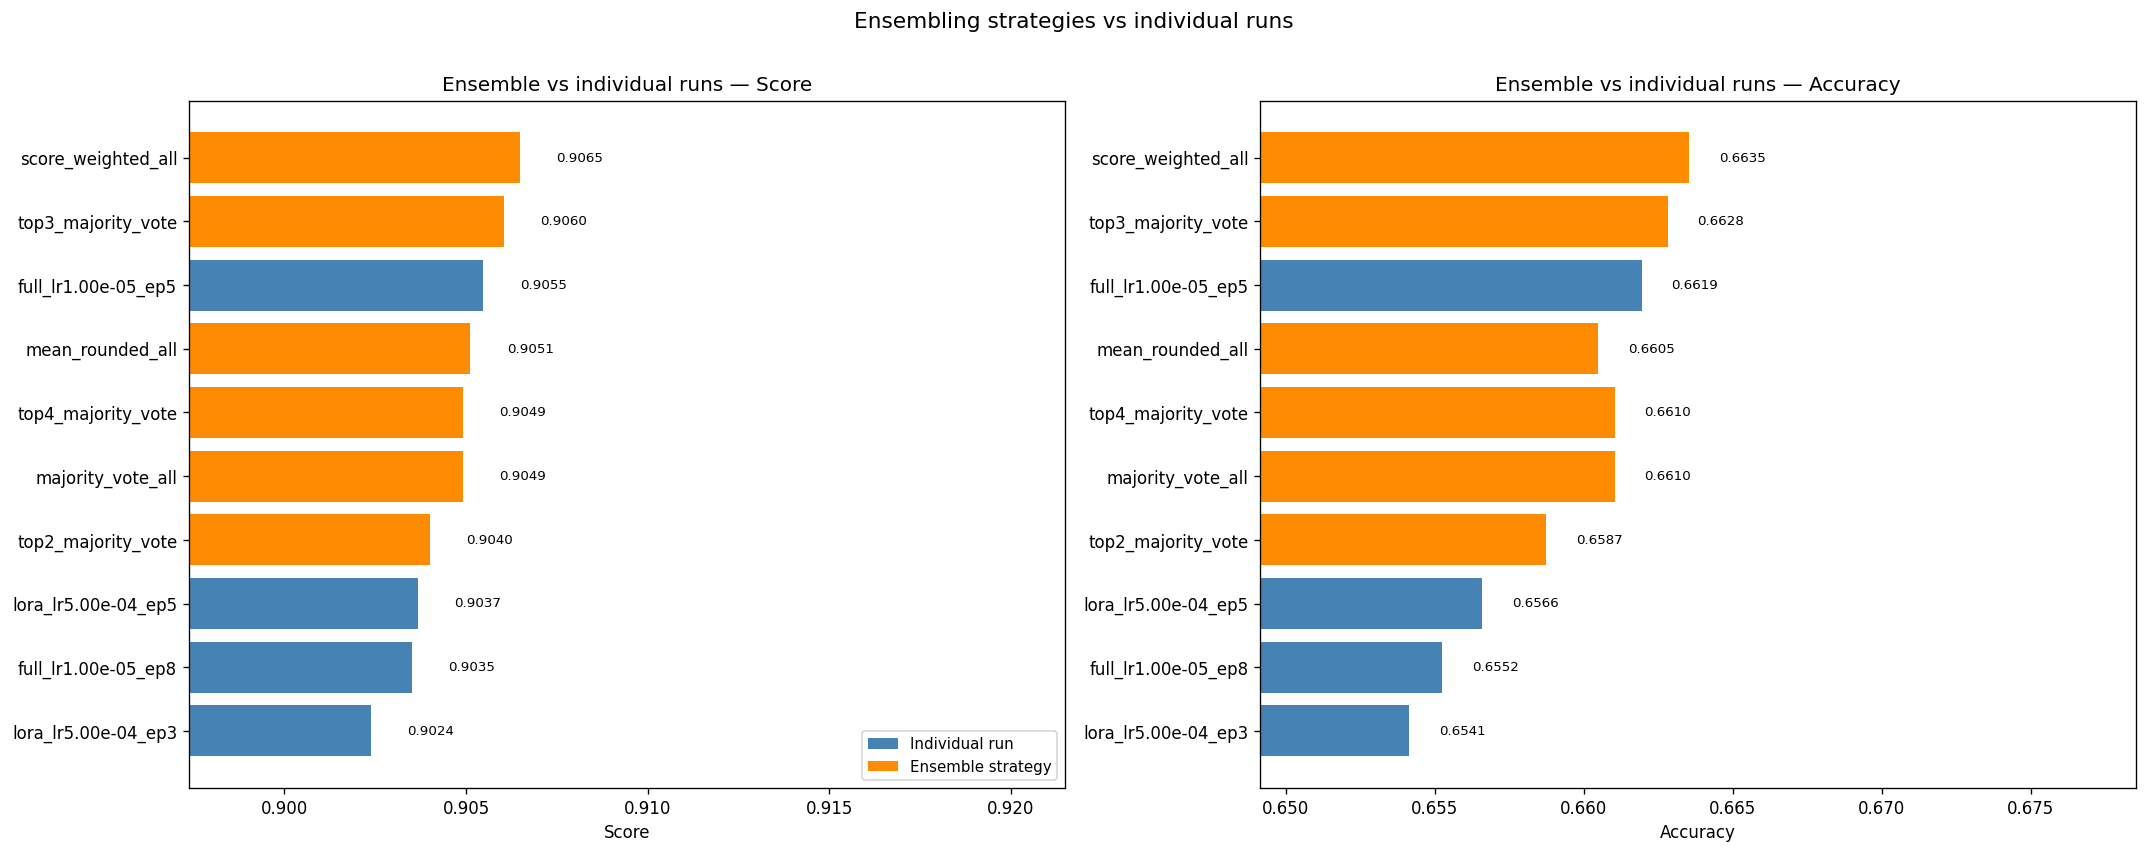

In [59]:
# ── bar chart: score & accuracy for every strategy ───────────────────────────

colors = {"individual": "steelblue", "ensemble": "darkorange"}
sorted_ens = ens_df.sort_values("score", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

for ax, metric in zip(axes, ["score", "accuracy"]):
    bar_colors = [colors[t] for t in sorted_ens["type"]]
    bars = ax.barh(sorted_ens["label"], sorted_ens[metric], color=bar_colors)
    ax.set_xlabel(metric.capitalize())
    ax.set_title(f"Ensemble vs individual runs — {metric.capitalize()}")
    x_min = sorted_ens[metric].min() - 0.005
    x_max = sorted_ens[metric].max() + 0.015
    ax.set_xlim(x_min, x_max)
    for bar, val in zip(bars, sorted_ens[metric]):
        ax.text(val + 0.001, bar.get_y() + bar.get_height() / 2,
                f"{val:.4f}", va="center", fontsize=8)

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor="steelblue", label="Individual run"),
                   Patch(facecolor="darkorange", label="Ensemble strategy")]
axes[0].legend(handles=legend_elements, loc="lower right", fontsize=9)

plt.suptitle("Ensembling strategies vs individual runs", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

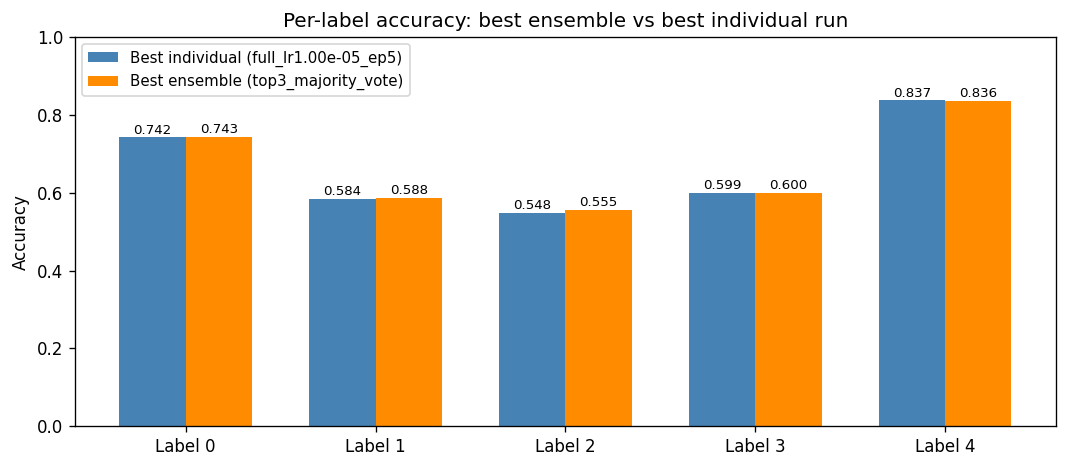

In [49]:
# ── per-label accuracy of best ensemble vs best individual run ────────────────

best_ensemble_label = ens_df[ens_df["type"] == "ensemble"].iloc[0]["label"]
best_individual_label = ens_df[ens_df["type"] == "individual"].iloc[0]["label"]

# Re-derive predictions for both
def get_ensemble_pred(label):
    if label == "majority_vote_all":
        return majority_vote(pred_matrix)
    if label == "mean_rounded_all":
        return np.clip(np.round(pred_matrix.mean(axis=1)), 0, 4).astype(int)
    if label == "score_weighted_all":
        w = run_scores / run_scores.sum()
        return np.clip(np.round((pred_matrix * w).sum(axis=1)), 0, 4).astype(int)
    if label.startswith("top") and "majority" in label:
        k = int(label[3])
        top_k_idx = np.argsort(run_scores)[::-1][:k]
        return majority_vote(pred_matrix[:, top_k_idx])
    # individual run
    idx = short_run_names.index(label)
    return pred_matrix[:, idx]

best_ens_pred  = get_ensemble_pred(best_ensemble_label)
best_ind_idx   = short_run_names.index(best_individual_label)
best_ind_pred  = pred_matrix[:, best_ind_idx]

label_ids = np.arange(5)
ens_per_label_acc  = [(true_labels[true_labels == l] == best_ens_pred[true_labels == l]).mean() for l in label_ids]
ind_per_label_acc  = [(true_labels[true_labels == l] == best_ind_pred[true_labels == l]).mean() for l in label_ids]

x = np.arange(5)
width = 0.35
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - width/2, ind_per_label_acc, width, label=f"Best individual ({best_individual_label})", color="steelblue")
ax.bar(x + width/2, ens_per_label_acc, width, label=f"Best ensemble ({best_ensemble_label})", color="darkorange")
ax.set_xticks(x)
ax.set_xticklabels([f"Label {i}" for i in label_ids])
ax.set_ylabel("Accuracy")
ax.set_title("Per-label accuracy: best ensemble vs best individual run")
ax.legend(fontsize=9)
ax.set_ylim(0, 1)
for xi, (iv, ev) in enumerate(zip(ind_per_label_acc, ens_per_label_acc)):
    ax.text(xi - width/2, iv + 0.01, f"{iv:.3f}", ha="center", fontsize=8)
    ax.text(xi + width/2, ev + 0.01, f"{ev:.3f}", ha="center", fontsize=8)
plt.tight_layout()
plt.show()

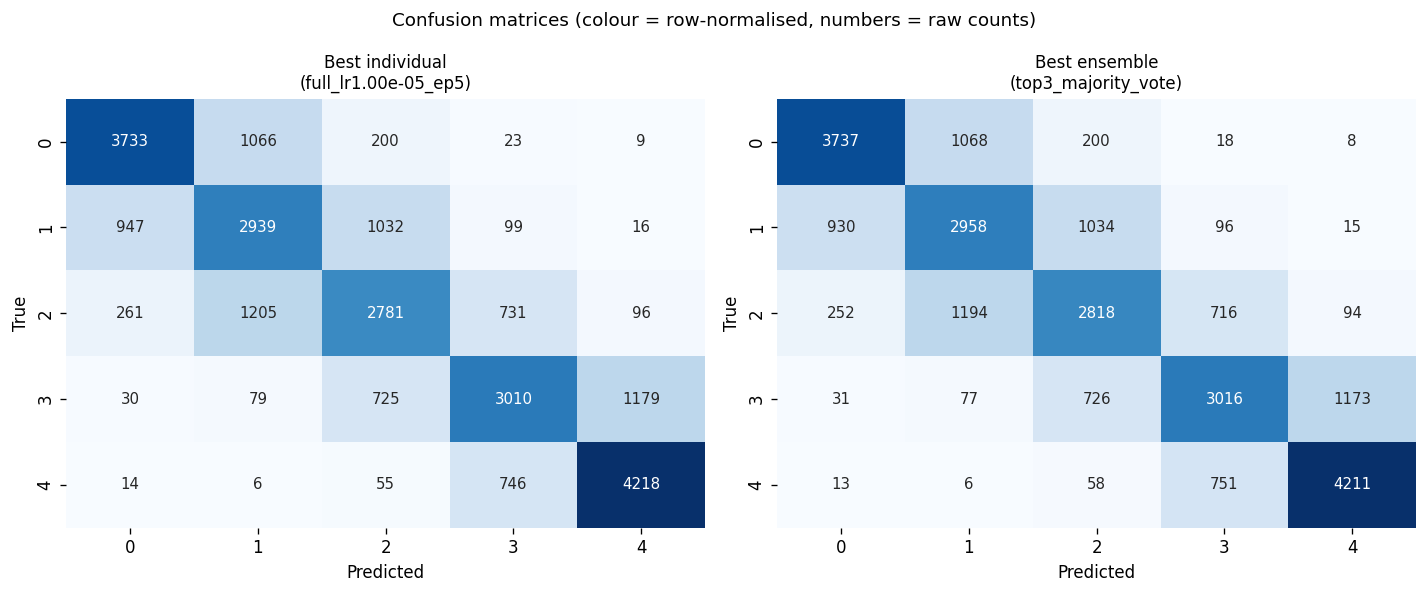

In [50]:
# ── confusion matrix of the best ensemble strategy ───────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
LABELS_LIST = [0, 1, 2, 3, 4]

for ax, (pred, title) in zip(axes, [
        (best_ind_pred, f"Best individual\n({best_individual_label})"),
        (best_ens_pred, f"Best ensemble\n({best_ensemble_label})")]):
    cm = confusion_matrix(true_labels, pred, labels=LABELS_LIST)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_norm, annot=cm, fmt="d", ax=ax, cmap="Blues",
                xticklabels=LABELS_LIST, yticklabels=LABELS_LIST,
                cbar=False, annot_kws={"size": 9})
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")

plt.suptitle("Confusion matrices (colour = row-normalised, numbers = raw counts)", fontsize=11)
plt.tight_layout()
plt.show()

Samples where ensemble GAINED over best individual : 502
Samples where ensemble LOST vs best individual     : 432
Both still wrong                                   : 8,017
Net change in correct predictions                  : +70


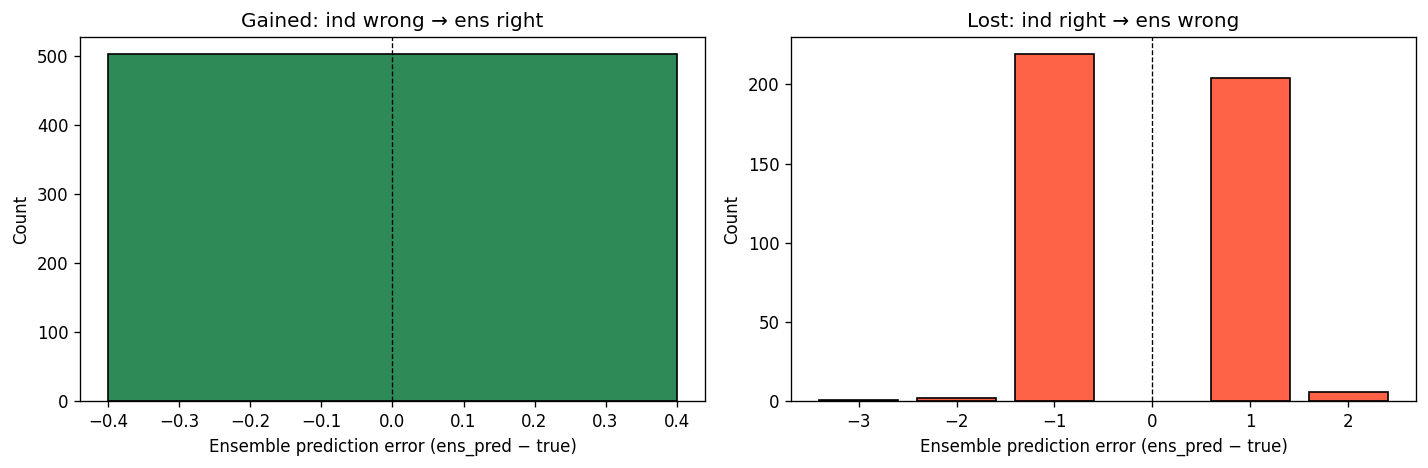

In [37]:
# ── disagreement analysis: where does the ensemble help / hurt? ──────────────

# Find samples where ensemble and best individual disagree
ens_correct = best_ens_pred == true_labels
ind_correct = best_ind_pred == true_labels

gained = (~ind_correct) & ens_correct   # individual wrong, ensemble right
lost   = ind_correct & (~ens_correct)   # individual right, ensemble wrong
both_wrong = (~ind_correct) & (~ens_correct)

print(f"Samples where ensemble GAINED over best individual : {gained.sum():,}")
print(f"Samples where ensemble LOST vs best individual     : {lost.sum():,}")
print(f"Both still wrong                                   : {both_wrong.sum():,}")
print(f"Net change in correct predictions                  : {gained.sum() - lost.sum():+,}")

# Error distribution for gained / lost cases
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, mask, title, color in [
        (axes[0], gained, "Gained: ind wrong → ens right", "seagreen"),
        (axes[1], lost,   "Lost: ind right → ens wrong", "tomato")]:
    if mask.sum() == 0:
        ax.text(0.5, 0.5, "No samples", ha="center", va="center", transform=ax.transAxes)
        ax.set_title(title)
        continue
    errors = best_ens_pred[mask] - true_labels[mask]
    ec = pd.Series(errors).value_counts().sort_index()
    ax.bar(ec.index, ec.values, color=color, edgecolor="black")
    ax.set_xlabel("Ensemble prediction error (ens_pred − true)")
    ax.set_ylabel("Count")
    ax.set_title(title)
    ax.axvline(0, color="black", linewidth=0.8, linestyle="--")

plt.tight_layout()
plt.show()

## 14. Stacking: train a meta-classifier on run predictions

Instead of hand-crafted combination rules, a small meta-classifier learns *which runs to trust and how* directly from the data.

**Setup:** the validation set is split 50 / 50 into a *meta-train* fold (used to fit the meta-classifier) and a *meta-test* fold (held out for fair evaluation). Features are the raw integer predictions of each individual run; the target is the true label.

Three meta-classifiers are compared:

| Meta-classifier | Notes |
|---|---|
| **Logistic Regression** | Linear combination of run predictions per class |
| **Ordinal Ridge** | Treat as regression, round to nearest int (respects label ordering) |
| **Random Forest** | Non-linear; can capture inter-run interactions |


In [51]:
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# ── meta-train / meta-test split ─────────────────────────────────────────────
X = pred_matrix.astype(float)   # (n_samples, n_runs)
y = true_labels                  # (n_samples,)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.5, random_state=42, stratify=y)

print(f"Meta-train : {len(X_train):,} samples")
print(f"Meta-test  : {len(X_test):,} samples")
print(f"Features   : {X_train.shape[1]} runs  → {short_run_names}")

# ── train meta-classifiers ────────────────────────────────────────────────────
meta_models = {
    "LogReg (C=1)":      LogisticRegression(C=1.0, max_iter=500, random_state=42),
    "LogReg (C=0.1)":    LogisticRegression(C=0.1, max_iter=500, random_state=42),
    "Ridge (α=1)":       Ridge(alpha=1.0),
    "Ridge (α=0.1)":     Ridge(alpha=0.1),
    "RandomForest":      RandomForestClassifier(n_estimators=200, max_depth=6,
                                                random_state=42, n_jobs=-1),
}

meta_results = []

for name, model in meta_models.items():
    model.fit(X_train, y_train)

    if isinstance(model, Ridge):
        raw = model.predict(X_test)
        pred = np.clip(np.round(raw), 0, 4).astype(int)
    else:
        pred = model.predict(X_test).astype(int)

    acc, sc = compute_metrics(y_test, pred)
    meta_results.append({"label": name, "type": "meta-classifier", "accuracy": acc, "score": sc})
    print(f"  {name:20s}  score={sc:.4f}  acc={acc:.4f}")

meta_df = pd.DataFrame(meta_results)

Meta-train : 12,600 samples
Meta-test  : 12,600 samples
Features   : 6 runs  → ['full_lr1.00e-05_ep5', 'full_lr1.00e-05_ep8', 'full_lr2.00e-05_ep5', 'full_lr5.00e-05_ep5', 'full_lr5.00e-05_ep8', 'full_lr8.00e-06_ep5']
  LogReg (C=1)          score=0.9066  acc=0.6629
  LogReg (C=0.1)        score=0.9067  acc=0.6632
  Ridge (α=1)           score=0.9063  acc=0.6587
  Ridge (α=0.1)         score=0.9063  acc=0.6587
  RandomForest          score=0.9070  acc=0.6637


In [52]:
# ── compare meta-classifiers vs simple ensembles vs best individual ───────────
# Re-evaluate simple strategies on the meta-test split for a fair comparison
X_test_int = X_test.astype(int)

baselines = []

# Best individual run (on meta-test split)
best_ind_test = X_test_int[:, best_ind_idx]
acc, sc = compute_metrics(y_test, best_ind_test)
baselines.append({"label": f"best_individual\n({best_individual_label})", "type": "individual", "accuracy": acc, "score": sc})

# Simple ensembles on meta-test split
mv_test = majority_vote(X_test_int)
acc, sc = compute_metrics(y_test, mv_test)
baselines.append({"label": "majority_vote_all", "type": "ensemble", "accuracy": acc, "score": sc})

mean_test = np.clip(np.round(X_test.mean(axis=1)), 0, 4).astype(int)
acc, sc = compute_metrics(y_test, mean_test)
baselines.append({"label": "mean_rounded_all", "type": "ensemble", "accuracy": acc, "score": sc})

w = run_scores / run_scores.sum()
wm_test = np.clip(np.round((X_test * w).sum(axis=1)), 0, 4).astype(int)
acc, sc = compute_metrics(y_test, wm_test)
baselines.append({"label": "score_weighted_all", "type": "ensemble", "accuracy": acc, "score": sc})

best_k = ens_df[ens_df["type"] == "ensemble"].iloc[0]["label"]
if best_k.startswith("top") and "majority" in best_k:
    k = int(best_k[3])
    top_k_idx = np.argsort(run_scores)[::-1][:k]
    topk_test = majority_vote(X_test_int[:, top_k_idx])
    acc, sc = compute_metrics(y_test, topk_test)
    baselines.append({"label": best_k, "type": "ensemble", "accuracy": acc, "score": sc})

compare_df = pd.concat([
    pd.DataFrame(baselines),
    meta_df,
], ignore_index=True).sort_values("score", ascending=False)

compare_df[["label", "type", "accuracy", "score"]].style.background_gradient(
    subset=["accuracy", "score"], cmap="RdYlGn")

,label,type,accuracy,score
9,RandomForest,meta-classifier,0.663730,0.907004
4,top3_majority_vote,ensemble,0.664683,0.906865
6,LogReg (C=0.1),meta-classifier,0.663175,0.906726
5,LogReg (C=1),meta-classifier,0.662937,0.906647
1,majority_vote_all,ensemble,0.664127,0.906567
2,mean_rounded_all,ensemble,0.662857,0.906567
7,Ridge (α=1),meta-classifier,0.658730,0.906329
8,Ridge (α=0.1),meta-classifier,0.658730,0.906329
3,score_weighted_all,ensemble,0.660714,0.906171
0,best_individual (full_lr1.00e-05_ep5),individual,0.660873,0.905575


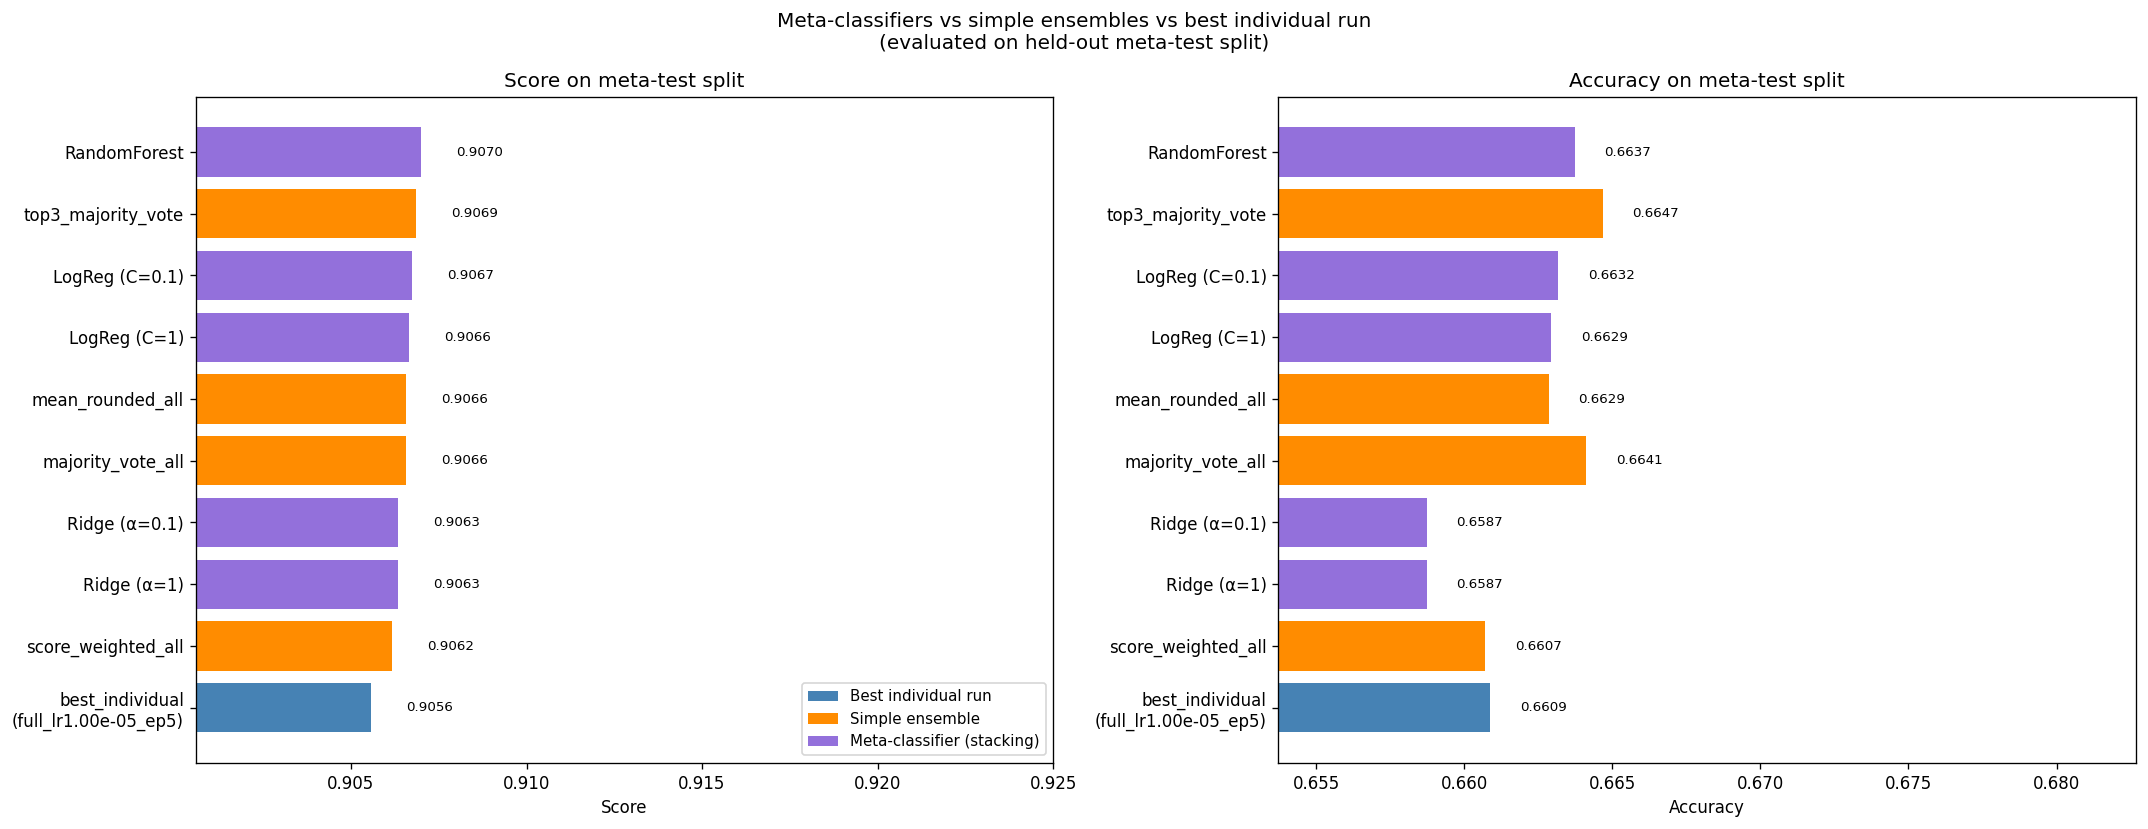

In [53]:
# ── bar chart: all strategies on the same meta-test split ────────────────────

color_map = {"individual": "steelblue", "ensemble": "darkorange", "meta-classifier": "mediumpurple"}
sorted_cmp = compare_df.sort_values("score", ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
for ax, metric in zip(axes, ["score", "accuracy"]):
    bar_colors = [color_map[t] for t in sorted_cmp["type"]]
    bars = ax.barh(sorted_cmp["label"], sorted_cmp[metric], color=bar_colors)
    x_min = sorted_cmp[metric].min() - 0.005
    x_max = sorted_cmp[metric].max() + 0.018
    ax.set_xlim(x_min, x_max)
    for bar, val in zip(bars, sorted_cmp[metric]):
        ax.text(val + 0.001, bar.get_y() + bar.get_height() / 2,
                f"{val:.4f}", va="center", fontsize=8)
    ax.set_xlabel(metric.capitalize())
    ax.set_title(f"{metric.capitalize()} on meta-test split")

legend_elements = [
    Patch(facecolor="steelblue",    label="Best individual run"),
    Patch(facecolor="darkorange",   label="Simple ensemble"),
    Patch(facecolor="mediumpurple", label="Meta-classifier (stacking)"),
]
axes[0].legend(handles=legend_elements, loc="lower right", fontsize=9)
plt.suptitle("Meta-classifiers vs simple ensembles vs best individual run\n(evaluated on held-out meta-test split)", fontsize=12)
plt.tight_layout()
plt.show()

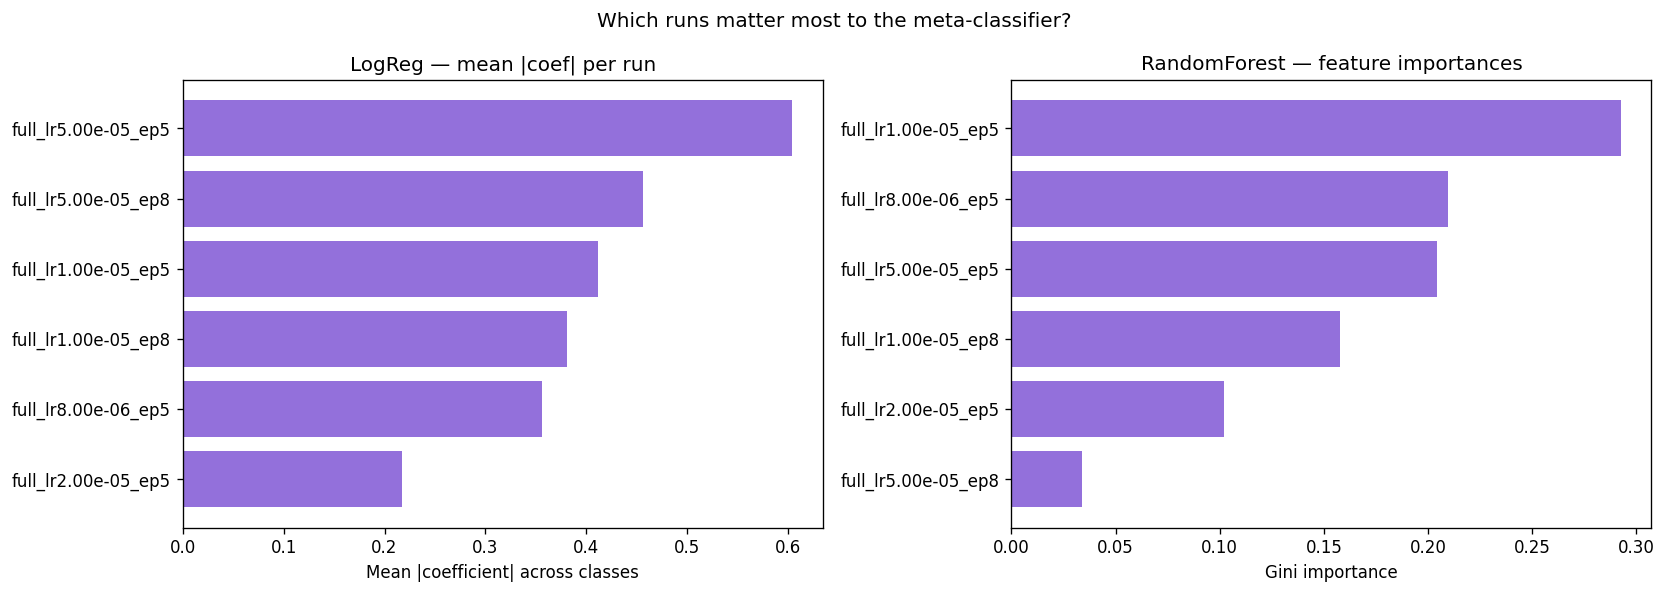

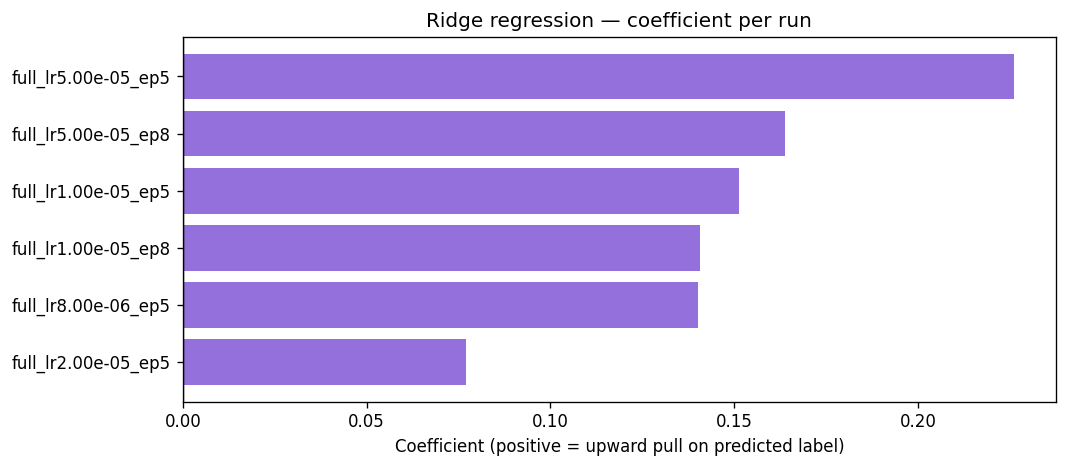

In [54]:
# ── feature importance: which runs does the meta-classifier rely on? ──────────

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# LogReg: coefficient magnitude per run (averaged across classes)
logreg = meta_models["LogReg (C=1)"]
logreg_importance = np.abs(logreg.coef_).mean(axis=0)
order = np.argsort(logreg_importance)
axes[0].barh([short_run_names[i] for i in order], logreg_importance[order], color="mediumpurple")
axes[0].set_title("LogReg — mean |coef| per run")
axes[0].set_xlabel("Mean |coefficient| across classes")

# Random Forest: feature importances
rf = meta_models["RandomForest"]
rf_importance = rf.feature_importances_
order = np.argsort(rf_importance)
axes[1].barh([short_run_names[i] for i in order], rf_importance[order], color="mediumpurple")
axes[1].set_title("RandomForest — feature importances")
axes[1].set_xlabel("Gini importance")

plt.suptitle("Which runs matter most to the meta-classifier?", fontsize=12)
plt.tight_layout()
plt.show()

# Ridge: weights (one scalar per run)
ridge = meta_models["Ridge (α=1)"]
ridge_w = ridge.coef_
order = np.argsort(ridge_w)
fig2, ax2 = plt.subplots(figsize=(9, 4))
colors_ridge = ["tomato" if w < 0 else "mediumpurple" for w in ridge_w[order]]
ax2.barh([short_run_names[i] for i in order], ridge_w[order], color=colors_ridge)
ax2.axvline(0, color="black", linewidth=0.8)
ax2.set_title("Ridge regression — coefficient per run")
ax2.set_xlabel("Coefficient (positive = upward pull on predicted label)")
plt.tight_layout()
plt.show()